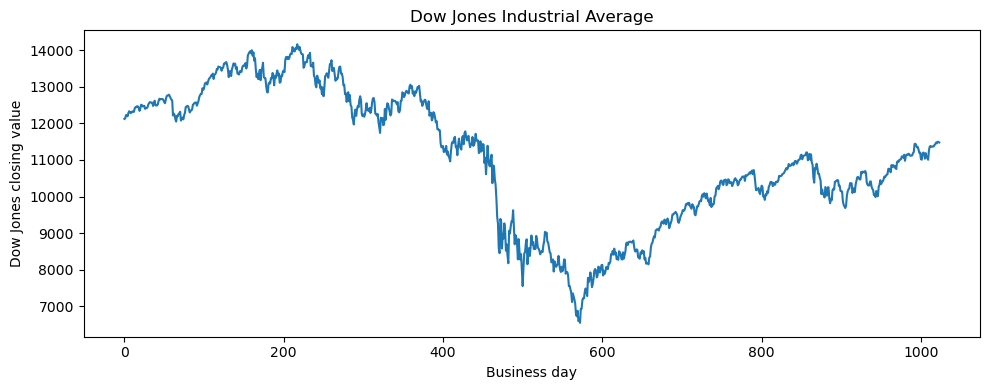

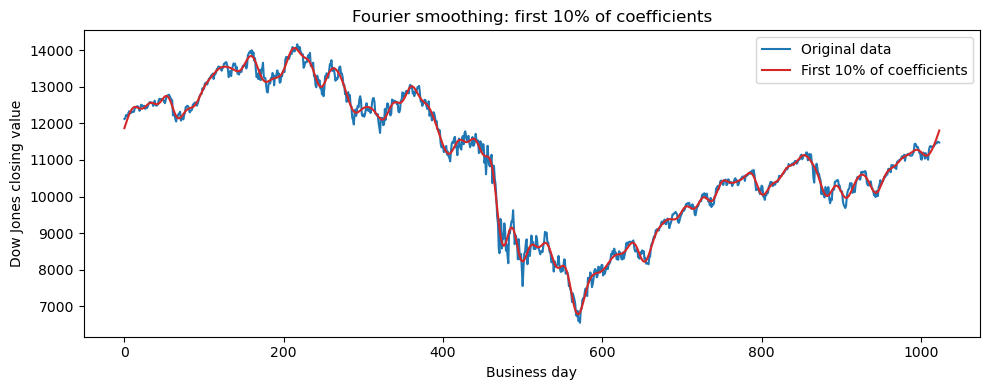

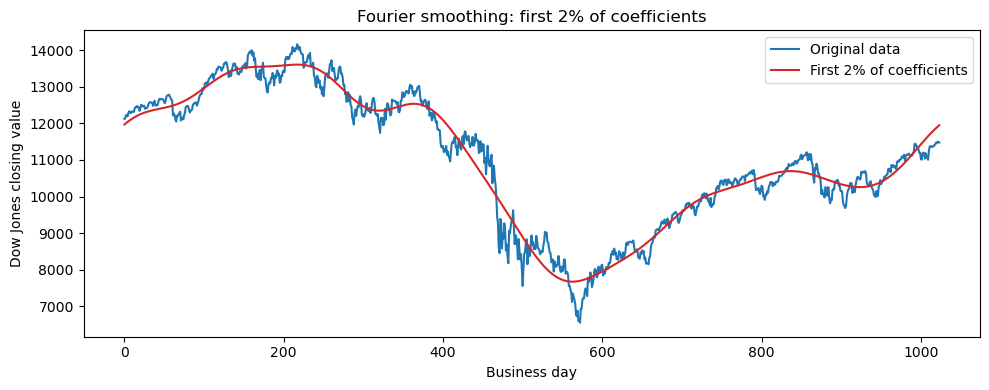

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# (a) Plot data 
y = np.loadtxt("/Users/nichaeadnan/Desktop/dow.txt")
N = len(y)

plt.figure(figsize=(10, 4))
plt.plot(y)
plt.xlabel("Business day")
plt.ylabel("Dow Jones closing value")
plt.title("Dow Jones Industrial Average")
plt.tight_layout()
plt.savefig("/Users/nichaeadnan/Desktop/dow_original.png", dpi=150)

# (b) Fourier coefficients using rfft (N/2 + 1 complex numbers)
c = np.fft.rfft(y)

def smooth(c, fraction):
    """Keep the first `fraction` of the coefficients, zero the rest, and invert."""
    c_filtered = c.copy()
    cutoff = int(fraction * len(c))
    c_filtered[cutoff:] = 0
    return np.fft.irfft(c_filtered, n=N)   # n=N keeps the original length

# (c), (d) 
y10 = smooth(c, 0.10)

plt.figure(figsize=(10, 4))
plt.plot(y, color="tab:blue", label="Original data")
plt.plot(y10, color="tab:red", label="First 10% of coefficients")
plt.xlabel("Business day")
plt.ylabel("Dow Jones closing value")
plt.title("Fourier smoothing: first 10% of coefficients")
plt.legend()
plt.tight_layout()
plt.savefig("/Users/nichaeadnan/Desktop/dow_10percent.png", dpi=150)

# (e) 
y2 = smooth(c, 0.02)

plt.figure(figsize=(10, 4))
plt.plot(y, color="tab:blue", label="Original data")
plt.plot(y2, color="tab:red", label="First 2% of coefficients")
plt.xlabel("Business day")
plt.ylabel("Dow Jones closing value")
plt.title("Fourier smoothing: first 2% of coefficients")
plt.legend()
plt.tight_layout()
plt.savefig("/Users/nichaeadnan/Desktop/dow_2percent.png", dpi=150)

plt.show()